# Housing Price Prediction Notebook

In this notebook, prediction models will be built on the data from `../data/housing.csv` to predict median house values using different features.

# Objectives

This project builds a supervised prediction pipeline using the housing dataset. This will cover:

- Exploratory data analysis 

- Data Preprocessing (Standard Scaling, Inputation and train/test split)

- Model training (Ridge and Lasso regression)

- Hyperparameter tuning using GridSearchCV

- Model evaluation: predicted vs actual values

- Residual distribution

## Load data

In this step, we load the housing dataset using pandas.

In [1]:
# Import libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Read data
data = pd.read_csv("../data/housing.csv")

# Create copy
df_housing = data.copy()

In [3]:
# Display information on data
# df_housing.info()
df_housing.shape

(20640, 10)

In [11]:
# Display data
df_housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## Explore

Here, we explore the dataset and derive more insights, before we proceed to preprocessing and model building.

In [7]:
# Checking for nulls
df_housing.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [10]:
# Checking for percentage of missing values
(df_housing.isna().sum() / len(df_housing)) * 100

longitude             0.000000
latitude              0.000000
housing_median_age    0.000000
total_rooms           0.000000
total_bedrooms        1.002907
population            0.000000
households            0.000000
median_income         0.000000
median_house_value    0.000000
ocean_proximity       0.000000
dtype: float64

Only the `total_bedrooms` feature has missing data (about ~1%). However, this will be handled in our preprocessing step before model building. We proceed to explore relationships between the different features.

In [57]:
# Check for duplicates
df_housing.duplicated().sum()

np.int64(0)

Our data currently has no duplicates. We continue exploring.

In [ ]:
# Display correlation matrix
df_housing.corr(numeric_only=True)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069608,0.099773,0.055310,-0.015176,-0.045967
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066983,-0.108785,-0.071035,-0.079809,-0.144160
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.320451,-0.296244,-0.302916,-0.119034,0.105623
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.930380,0.857126,0.918484,0.198050,0.134153
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.099773,-0.108785,-0.296244,0.857126,0.877747,1.000000,0.907222,0.004834,-0.024650
households,0.055310,-0.071035,-0.302916,0.918484,0.979728,0.907222,1.000000,0.013033,0.065843
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007723,0.004834,0.013033,1.000000,0.688075
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049686,-0.024650,0.065843,0.688075,1.000000


We see a very strong correlation between population and households, households and total_bedrooms, among others. These relationships are typical of house prediction datasets.

However, the very weak correlation between `total_bedrooms` vs `median_house_value`, and `median_income` vs `total_bedrooms` needs a deeper look

Let's explore the correlation coefficients on the data subset using different `ocean_proximity` values

In [72]:
# Get unique ocean proximity values
# df_housing["ocean_proximity"].unique()
# ['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND']
mask_ocean = df_housing["ocean_proximity"] == "ISLAND"
df_subset = df_housing[mask_ocean]
df_subset.corr(numeric_only=True)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.983060,0.551132,0.648557,0.655256,0.411459,0.470430,0.171846,0.638864
latitude,-0.983060,1.000000,-0.676618,-0.707211,-0.667907,-0.446718,-0.480653,-0.343587,-0.521291
housing_median_age,0.551132,-0.676618,1.000000,0.462667,0.250360,0.236557,0.171587,0.764794,0.093969
total_rooms,0.648557,-0.707211,0.462667,1.000000,0.964567,0.916817,0.902955,0.392159,0.127076
total_bedrooms,0.655256,-0.667907,0.250360,0.964567,1.000000,0.926034,0.945329,0.151551,0.252519
population,0.411459,-0.446718,0.236557,0.916817,0.926034,1.000000,0.989634,0.136258,0.154042
households,0.470430,-0.480653,0.171587,0.902955,0.945329,0.989634,1.000000,0.023268,0.265224
median_income,0.171846,-0.343587,0.764794,0.392159,0.151551,0.136258,0.023268,1.000000,-0.539913
median_house_value,0.638864,-0.521291,0.093969,0.127076,0.252519,0.154042,0.265224,-0.539913,1.000000


### Feature Distributions

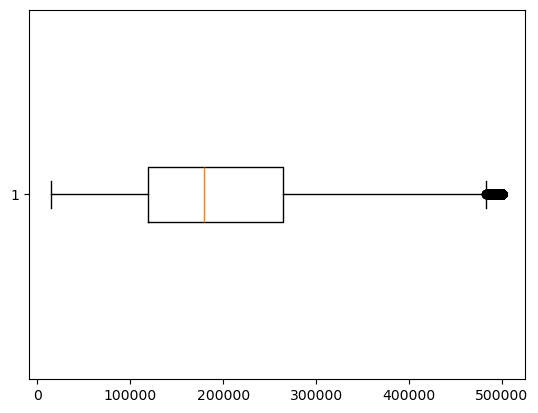

In [64]:
# df_housing["median_house_value"].hist()
plt.boxplot(df_housing["median_house_value"], vert=False);

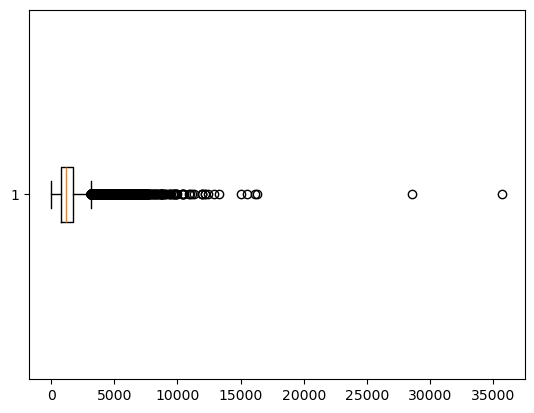

In [ ]:
plt.boxplot(df_housing["median_income"], vert=False);

<Axes: >

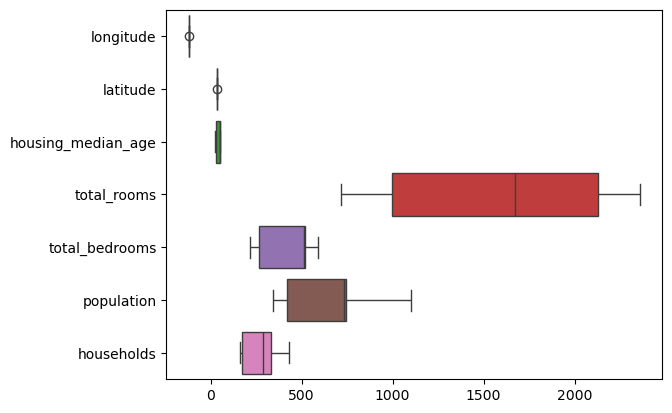

In [ ]:
sns.boxplot(df_housing.drop(columns=["ocean_proximity","median_house_value", "median_income"]), orient='h')

### Exploring relationships

#### Bedrooms vs House value

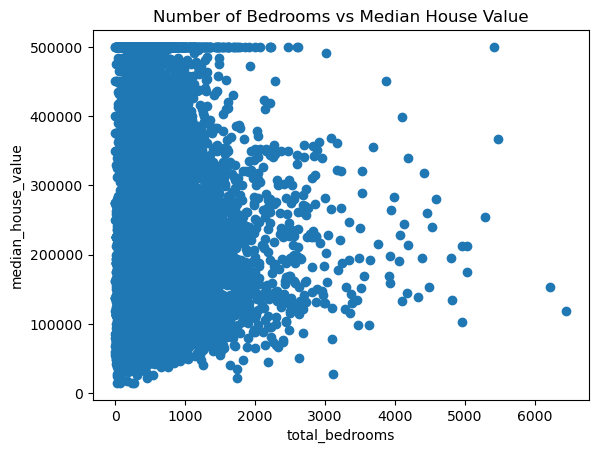

In [11]:
# Bedrooms vs House value
plt.scatter(x=df_housing["total_bedrooms"], y= df_housing["median_house_value"]);
plt.title("Number of Bedrooms vs Median House Value")
plt.xlabel("total_bedrooms")
plt.ylabel("median_house_value")
plt.show()

#### Income and Bedroom 

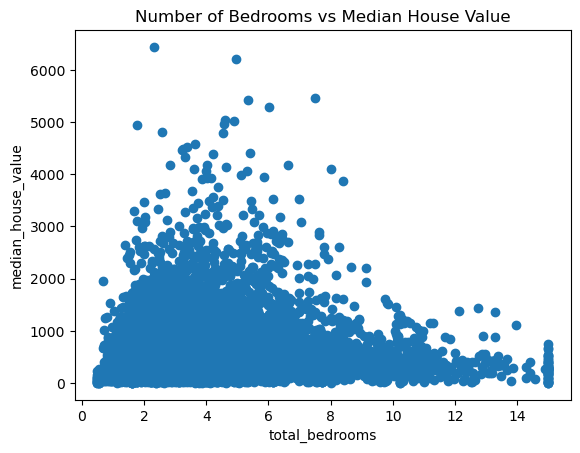

In [14]:
# Income vs Bedrooms
plt.scatter(x=df_housing["median_income"], y= df_housing["total_bedrooms"]);
plt.title("Number of Bedrooms vs Median House Value")
plt.xlabel("total_bedrooms")
plt.ylabel("median_house_value")
plt.show()

### Correlation Heatmap

<Axes: >

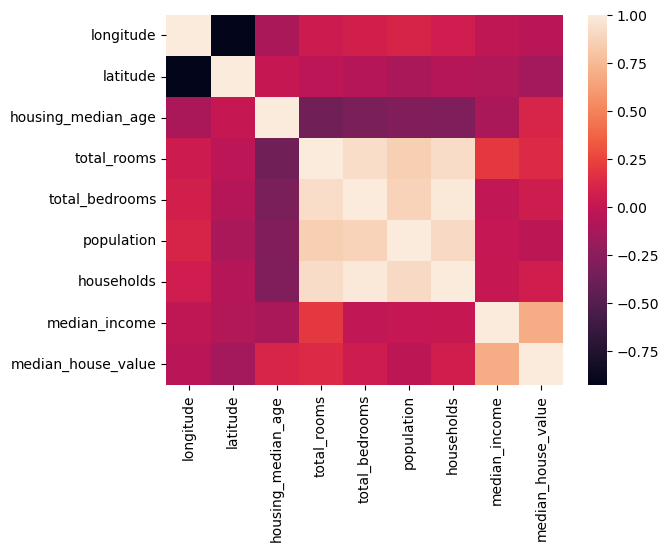

In [16]:
sns.heatmap(df_housing.corr(numeric_only=True))

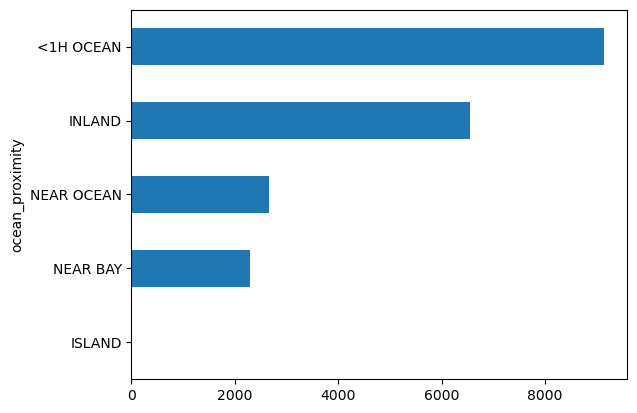

In [ ]:
# Ocean distribution distribution
(df_housing["ocean_proximity"].
    value_counts().
    sort_values().
    plot(kind="barh")
);

## Feature Engineering